# 01 Phase 3 completion

## Mangrove resilience, Gulf of Carpentaria

## 0. Setup

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)

# paths 
ROOT    = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA    = ROOT / "data"
FIGDIR  = ROOT / "figures"
TABDIR  = ROOT / "tables"
FIGDIR.mkdir(exist_ok=True); TABDIR.mkdir(exist_ok=True)

# analysis constants 
RECOVERY_FRAC = 0.80      # recovery threshold
LAST_YEAR     = 2025      # end of the observation record
BLOCK_DEG     = 0.25      # spatial block size for the bootstrap (~27 km)
CELL_DEG      = 0.045     # coastal segment size (~5 km)
MIN_SEG_PIX   = 30        
N_BOOT        = 2000
SEED          = 2026
RNG           = np.random.default_rng(SEED)
NODATA        = -9999
PIXEL_HA      = 2522.33 / 29453

# figure style (Okabe-Ito, CVD-validated) 
C_DIEBACK, C_REF = "#D55E00", "#0072B2"
C_INK, C_MUTED, C_GRID = "#1a1a1a", "#6b6b6b", "#e0e0e0"
W1, W2 = 3.50, 7.20                     

plt.rcParams.update({
    "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 9,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.edgecolor": C_MUTED, "axes.linewidth": 0.6,
    "xtick.color": C_MUTED, "ytick.color": C_MUTED,
    "text.color": C_INK, "axes.labelcolor": C_INK,
    "figure.dpi": 150, "savefig.dpi": 400, "savefig.bbox": "tight",
})

def tidy(ax):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(True, color=C_GRID, lw=0.5)
    ax.set_axisbelow(True)
    return ax

RESULTS = {}     
print("root:", ROOT)

root: C:\mangrove-resilience


## 1a. Build the pixel table from the rasters

In [2]:
BUILD_FROM_RASTERS = False      

RASTER_RESILIENCE = DATA / "rasters" / "resilience_2015_16_30m.tif"
RASTER_CLASSMAP   = DATA / "rasters" / "classmap_fullcoast_30m.tif"
DIEBACK_CLASS     = 2

if BUILD_FROM_RASTERS:
    import rasterio
    from rasterio.windows import Window

    with rasterio.open(RASTER_RESILIENCE) as src_r, \
         rasterio.open(RASTER_CLASSMAP)   as src_c:

        assert src_r.shape == src_c.shape, (
            f"rasters disagree: {src_r.shape} vs {src_c.shape}. ")
        band_names = list(src_r.descriptions)
        if not all(band_names):
            band_names = ["magnitude","recovery_ratio","recovery_ratio_adj",
                          "recovery_rate","recovery_rate_adj",
                          "years_to_recovery","unrecovered","pre_nbr",
                          "min_nbr","now_nbr","yod","year_min",
                          "climate_shift","has_ref","rmse"][:src_r.count]
        print("bands:", band_names)

        # Only dieback pixels are retained
        chunks, H, W = [], src_r.height, src_r.width
        STEP = 512
        for row in range(0, H, STEP):
            h = min(STEP, H - row)
            win = Window(0, row, W, h)
            cls = src_c.read(1, window=win)
            hit = np.flatnonzero((cls == DIEBACK_CLASS).ravel())
            if hit.size == 0:
                continue
            vals = src_r.read(window=win).reshape(src_r.count, -1)[:, hit]
            rr, cc = np.divmod(hit, W)
            xs, ys = rasterio.transform.xy(src_r.window_transform(win),
                                           rr, cc, offset="center")
            d = {"longitude": np.asarray(xs), "latitude": np.asarray(ys)}
            for i, nm in enumerate(band_names):
                d[nm] = vals[i]
            chunks.append(pd.DataFrame(d))

        px_built = pd.concat(chunks, ignore_index=True)

    px_built = px_built.replace(NODATA, np.nan)
    px_built.to_csv(DATA / "phase3_pixels.csv", index=False)
    print(f"\nbuilt {len(px_built):,} dieback pixels "
          f"({len(px_built)*0.09:,.1f} ha)  ->  data/phase3_pixels.csv")

## 1b. Load and validate

In [3]:
px = pd.read_csv(DATA / "phase3_pixels.csv")
px = px.replace(NODATA, np.nan)

EXPECTED = ["longitude","latitude","magnitude","recovery_ratio","recovery_ratio_adj",
            "recovery_rate","recovery_rate_adj","years_to_recovery","unrecovered",
            "pre_nbr","min_nbr","now_nbr","yod","year_min","climate_shift",
            "has_ref","rmse"]
missing = [c for c in EXPECTED if c not in px.columns]
if missing:
    print(f"note: columns absent from this build: {missing}")
    
    critical = [c for c in missing
                if c not in ("yod","year_min","has_ref","rmse")]
    assert not critical, f"missing critical columns: {critical}"
    for c in missing:
        px[c] = np.nan

print(f"rows                : {len(px):,}   (expect ~29,453)")
print(f"yod values          : {sorted(px.yod.dropna().unique().tolist()) or 'not in this build'}")
print(f"unrecovered flag    : {px.unrecovered.value_counts(dropna=False).to_dict()}")
nan_by_col = px.isna().sum()
nan_by_col = nan_by_col[nan_by_col > 0]
print("\nnodata by column (expected: years_to_recovery, for pixels that never recovered):")
print(nan_by_col.to_string() if len(nan_by_col) else "  none")

if len(px) < 25000:
    print("\n*** WARNING: far fewer rows than expected. The export is partial. ***")

RESULTS["n_pixels"] = int(len(px))
RESULTS["area_ha"]  = float(len(px) * PIXEL_HA)     
px.head()

rows                : 29,453   (expect ~29,453)
yod values          : [2015.0, 2016.0]
unrecovered flag    : {0.0: 21585, 1.0: 7868}

nodata by column (expected: years_to_recovery, for pixels that never recovered):
years_to_recovery    7868


,longitude,latitude,magnitude,recovery_ratio,recovery_ratio_adj,recovery_rate,recovery_rate_adj,years_to_recovery,unrecovered,pre_nbr,min_nbr,now_nbr,yod,year_min,climate_shift,has_ref,rmse
0,138.618987,-16.769974,0.442650,1.276743,1.050201,0.062794,0.051652,6.0,0.0,0.476853,0.034203,0.599353,2015.0,2015.0,0.100279,0.007843,0.111291
1,138.619256,-16.769974,0.263425,1.378090,0.997418,0.040336,0.029194,6.0,0.0,0.309863,0.046438,0.409461,2015.0,2015.0,0.100279,0.007843,0.096612
2,138.618178,-16.770244,0.180397,2.896830,2.195209,0.087097,0.066002,5.0,0.0,0.279632,0.099235,0.621815,2016.0,2018.0,0.126571,0.007843,0.077116
3,138.618448,-16.770244,0.490607,0.981431,0.777034,0.068785,0.054460,9.0,0.0,0.604918,0.114311,0.595808,2015.0,2017.0,0.100279,0.007843,0.093234
4,138.618717,-16.770244,0.521684,0.783683,0.591462,0.045426,0.034284,10.0,0.0,0.667818,0.146134,0.554969,2015.0,2015.0,0.100279,0.007843,0.065397


## 2. A consistency fix

The headline recovery ratio is **ENSO-adjusted** - regional climate is
subtracted so that recovery is measured against undisturbed stands rather than
against a wet year. The unrecovered flag exported from Earth Engine was
not adjusted: it was tested against the raw fitted trajectory.

Because the climate shift is positive (stands gained condition from the
2021–22 La Nina), adjusting lowers recovery. So the unadjusted flag is
traditional and it under counts unrecovered area. 

| Measure | Question |
|---|---|
| `unrecovered` (from GEE) | Did this pixel **ever** reach the threshold, on the raw trajectory? |
| `below_thr_now` | Is this pixel **currently** below the threshold, after climate adjustment? |

These differ for pixels that recovered and then declined again. Both are
reported; the second is the one that pairs with the adjusted ratio.

In [4]:
px["below_thr_now"]     = (px.recovery_ratio     < RECOVERY_FRAC).astype(float)
px["below_thr_now_adj"] = (px.recovery_ratio_adj < RECOVERY_FRAC).astype(float)

frac = {
    "never_reached_raw (GEE flag)": px.unrecovered.mean(),
    "below_threshold_now_raw":      px.below_thr_now.mean(),
    "below_threshold_now_adjusted": px.below_thr_now_adj.mean(),
}
for k, v in frac.items():
    print(f"{k:32s} {v:6.3%}   {v*RESULTS['area_ha']:8.1f} ha")

# Sensitivity of the adjusted figure to where the threshold is drawn.
sens = {t: float((px.recovery_ratio_adj < t).mean()) for t in (0.70, 0.80, 0.90)}
print("\nadjusted, by threshold:",
      {k: f"{v:.1%}" for k, v in sens.items()})

RESULTS["unrecovered"] = {k: float(v) for k, v in frac.items()}
RESULTS["unrecovered_sensitivity_adj"] = sens

never_reached_raw (GEE flag)     26.714%      673.8 ha
below_threshold_now_raw          36.322%      916.2 ha
below_threshold_now_adjusted     44.372%     1119.2 ha

adjusted, by threshold: {0.7: '33.2%', 0.8: '44.4%', 0.9: '55.5%'}


## 3. The four resilience measures - Table 1

Medians and interquartile ranges are used away from means and standard deviations: the
distributions are skewed and bounded at zero, so a mean ± SD implies a symmetry
that is not there.

`years_to_recovery` is reported **only over pixels that recovered**. Averaging
it over all pixels would silently delete the unrecovered ones  so the most
important part of the result by treating "never" as if it were a number.

In [5]:
def describe(s, label, unit=""):
    s = pd.Series(s).dropna()
    return {"Measure": label, "Unit": unit, "n": len(s),
            "Median": s.median(), "Mean": s.mean(),
            "Q1": s.quantile(.25), "Q3": s.quantile(.75)}

rec = px[px.unrecovered == 0]

table1 = pd.DataFrame([
    describe(px.magnitude,          "Magnitude of loss",              "NBR"),
    describe(px.recovery_ratio,     "Recovery ratio, raw",            "–"),
    describe(px.recovery_ratio_adj, "Recovery ratio, ENSO-adjusted",  "–"),
    describe(px.recovery_rate,      "Recovery rate, raw",             "NBR/yr"),
    describe(px.recovery_rate_adj,  "Recovery rate, ENSO-adjusted",   "NBR/yr"),
    describe(rec.years_to_recovery, "Years to recovery (recovered only)", "yr"),
    describe(px.pre_nbr,            "Pre-disturbance NBR",            "NBR"),
    describe(px.min_nbr,            "Trough NBR",                     "NBR"),
    describe(px.now_nbr,            "Current NBR (2023–25)",          "NBR"),
    describe(px.climate_shift,      "Climate shift",                  "NBR"),
    describe(px.rmse,               "LandTrendr RMSE",                "NBR"),
]).round(4)

table1.to_csv(TABDIR / "table1_resilience.csv", index=False)
RESULTS["table1"] = table1.to_dict(orient="records")

# noise check
snr = px.magnitude.median() / px.rmse.median()
print(f"magnitude / RMSE = {snr:.1f} ")
RESULTS["signal_to_noise"] = float(snr)
table1

magnitude / RMSE = 6.2 


,Measure,Unit,n,Median,Mean,Q1,Q3
0,Magnitude of loss,NBR,29453,0.3378,0.3618,0.2470,0.4563
1,"Recovery ratio, raw",–,29453,0.9239,0.9263,0.6852,1.1704
2,"Recovery ratio, ENSO-adjusted",–,29453,0.8523,0.8537,0.6170,1.0963
3,"Recovery rate, raw",NBR/yr,29453,0.0371,0.0399,0.0241,0.0554
4,"Recovery rate, ENSO-adjusted",NBR/yr,29453,0.0344,0.0372,0.0220,0.0514
5,Years to recovery (recovered only),yr,21585,8.0000,7.3792,6.0000,9.0000
6,Pre-disturbance NBR,NBR,29453,0.6474,0.6265,0.5535,0.7162
7,Trough NBR,NBR,29453,0.2547,0.2647,0.1391,0.3977
8,Current NBR (2023–25),NBR,29453,0.6233,0.5885,0.5150,0.6928
9,Climate shift,NBR,29453,0.0194,0.0226,0.0063,0.0376


## 4. resistance and recovery independent?

**The proposal argues that *how far a stand fell* and
*how completely it came back* are distinct properties driven by different
processes, and that collapsing them into a single "resilience" score loses
information. If they were strongly correlated, that argument would fail — one
measure would carry the other.

**Neighbouring pixels are not
independent observations; mangrove condition is spatially autocorrelated over
hundreds of metres. With n ≈ 29,000, a conventional p-value would be
small for even a trivial correlation, because it assumes 29,000
independent samples when the effective number is far smaller. therefore ordinary correlation was not used.

**spatial block bootstrap method.** The coast is cut into 0.25° blocks
(~27 km). Whole blocks are resampled with replacement, so the autocorrelation
within a block is preserved and only genuinely independent units are
resampled. 

Because the relationship need not be linear
and the variables are not normal Spearman test was used rather than Pearson coefficient.


In [6]:
def block_bootstrap_spearman(x, y, lon, lat, n_boot=N_BOOT, block=BLOCK_DEG, rng=RNG):
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(lon) & np.isfinite(lat)
    x, y, lon, lat = np.asarray(x)[ok], np.asarray(y)[ok], np.asarray(lon)[ok], np.asarray(lat)[ok]

    bid = (np.floor(lon / block).astype(int).astype(str) + "_" +
           np.floor(lat / block).astype(int).astype(str))
    blocks, inv = np.unique(bid, return_inverse=True)
    idx_by_block = [np.flatnonzero(inv == k) for k in range(len(blocks))]

    nb = len(blocks)
    if ok.sum() < 10 or nb < 3:
        return {"rho": np.nan, "ci_low": np.nan, "ci_high": np.nan,
                "n_blocks": int(nb), "n_points": int(ok.sum()),
                "naive_p": np.nan,
                "note": "too few independent blocks for a bootstrap"}

    point = stats.spearmanr(x, y).statistic
    boot = np.empty(n_boot)
    for b in range(n_boot):
        pick = rng.integers(0, nb, nb)
        sel = np.concatenate([idx_by_block[p] for p in pick])
        boot[b] = stats.spearmanr(x[sel], y[sel]).statistic
    lo, hi = np.nanpercentile(boot, [2.5, 97.5])
    return {"rho": float(point), "ci_low": float(lo), "ci_high": float(hi),
            "n_blocks": int(nb), "n_points": int(ok.sum()),
            "naive_p": float(stats.spearmanr(x, y).pvalue)}

ind = block_bootstrap_spearman(px.magnitude, px.recovery_ratio_adj,
                               px.longitude, px.latitude)
print(f"Spearman rho          : {ind['rho']:+.3f}")
print(f"95% block-bootstrap CI: [{ind['ci_low']:+.3f}, {ind['ci_high']:+.3f}]")
print(f"spatial blocks        : {ind['n_blocks']}   pixels: {ind['n_points']:,}")
print(f"(naive p-value, NOT reported: {ind['naive_p']:.2e})")
RESULTS["independence_pixel"] = ind

Spearman rho          : -0.159
95% block-bootstrap CI: [-0.271, -0.031]
spatial blocks        : 52   pixels: 29,453
(naive p-value, NOT reported: 6.26e-167)


### 4b. Is that correlation real, or an artefact of the formula?

**The problem.** `recovery_ratio = (now − min) / (pre − min)` and
`magnitude = pre − min`. The magnitude sits in the denominator of the ratio, so
the two share terms. Any measurement error in `pre` or `min` pushes them apart
mechanically, producing a negative correlation even if none exists in nature.


**Answer** Repeat the test using pairs that share no term:

| Pair | Shares a term? |
|---|---|
| magnitude vs `recovery_ratio_adj` | **yes** - weak evidence on its own |
| magnitude vs `now_nbr` | **no** - the decisive test |
| magnitude vs (`pre_nbr` − `now_nbr`) | shares `pre` |
| magnitude vs `years_to_recovery` | **no** |

If the clean pairs agree in direction with the shared one, the relationship is
real. If only the shared pair shows it, it is arithmetic.

In [7]:
pairs = [
 ("magnitude vs recovery_ratio_adj", px.magnitude, px.recovery_ratio_adj, px, "shared denominator"),
 ("magnitude vs now_nbr",            px.magnitude, px.now_nbr,            px, "NO shared term"),
 ("magnitude vs deficit (pre-now)",  px.magnitude, px.pre_nbr-px.now_nbr, px, "shares pre"),
 ("magnitude vs years_to_recovery",  rec.magnitude, rec.years_to_recovery, rec, "NO shared term"),
 ("pre_nbr vs now_nbr",              px.pre_nbr,   px.now_nbr,            px, "NO shared term"),
]
rob = {}
for name, x, y, src, tag in pairs:
    r = block_bootstrap_spearman(x, y, src.longitude, src.latitude)
    clear = (r["ci_low"] > 0) or (r["ci_high"] < 0)
    print(f"{name:34s} rho={r['rho']:+.3f}  "
          f"CI [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]  {tag}"
          + ("   <-- clear of zero" if clear else ""))
    rob[name] = {**r, "shares_term": tag, "ci_clear_of_zero": bool(clear)}

RESULTS["independence_robustness"] = rob

# How much of the variance does resistance actually explain?
rho = rob["magnitude vs now_nbr"]["rho"]
print(f"\nrho^2 for the clean pair = {rho**2:.3f}")
print("Resistance and recovery are related but far from redundant: magnitude")
print(f"accounts for about {rho**2:.0%} of the rank variance in current condition,")
print("so reporting them as separate measures remains justified.")

magnitude vs recovery_ratio_adj    rho=-0.159  CI [-0.268, -0.033]  shared denominator   <-- clear of zero
magnitude vs now_nbr               rho=-0.185  CI [-0.312, -0.077]  NO shared term   <-- clear of zero
magnitude vs deficit (pre-now)     rho=+0.298  CI [+0.167, +0.435]  shares pre   <-- clear of zero
magnitude vs years_to_recovery     rho=+0.261  CI [+0.155, +0.359]  NO shared term   <-- clear of zero
pre_nbr vs now_nbr                 rho=+0.328  CI [+0.182, +0.468]  NO shared term   <-- clear of zero

rho^2 for the clean pair = 0.034
Resistance and recovery are related but far from redundant: magnitude
accounts for about 3% of the rank variance in current condition,
so reporting them as separate measures remains justified.


## 5. Kaplan–Meier — how long recovery takes

**The problem this solves.** 26–27% of pixels never reached the threshold. We
do not know that they take "a long time"; we know only that they had not
recovered by 2025. In survival analysis this is **right censoring**: the event
has not happened by the end of observation, and the observation ends for a
reason unrelated to the event.

Throwing those pixels away biases the answer optimistically (only fast
recoverers remain). Treating them as recovering in 2025 biases it the other
way. Kaplan–Meier uses them correctly: each censored pixel contributes to the
denominator up to the point it leaves, then stops.

**Greenwood's formula** gives the standard error of the survival estimate at
each time; the interval is computed on the complementary log-log scale so it
stays inside [0, 1] rather than running past 100% near the ends.

**Reading it:** the curve starts at 1.0 (nobody has recovered at year 0) and
falls as pixels recover. Where it flattens is where recovery effectively stops.
The height of the plateau is the fraction that never recovers.

Ref:
- Kennedy, R.E., Yang, Z. & Cohen, W.B. (2010) Detecting trends in forest disturbance and recovery using yearly Landsat time series: 1. LandTrendr — Temporal segmentation algorithms. Remote Sensing of Environment 114(12), 2897–2910
- Roy, D.P. et al. (2016) Characterization of Landsat-7 to Landsat-8 reflective wavelength and normalized difference vegetation index continuity. Remote Sensing of Environment 185, 57–70
- Kaplan, E.L. & Meier, P. (1958) Nonparametric estimation from incomplete observations. Journal of the American Statistical Association 53(282), 457–481
- Greenwood, M. (1926) The natural duration of cancer. Reports on Public Health and Medical Subjects No. 33, 1–26. HMSO, London
- Kalbfleisch, J.D. & Prentice, R.L. (2002) The Statistical Analysis of Failure Time Data, 2nd edn. Wiley
- Borgan, Ø. & Liestøl, K. (1990) A note on confidence intervals and bands for the survival function based on transformations. Scandinavian Journal of Statistics 17(1), 35–41


In [8]:
def kaplan_meier(duration, event):
    '''duration: years observed. event: 1 = recovered, 0 = censored at 2025.'''
    d = pd.DataFrame({"t": duration, "e": event}).dropna()
    d = d[d.t >= 0].sort_values("t")
    times = np.sort(d.t.unique())
    # Anchor the curve at (0, 1): at time zero nothing has recovered yet.
    out = [{"t": 0.0, "at_risk": len(d), "events": 0,
            "S": 1.0, "se": 0.0, "lo": 1.0, "hi": 1.0}]
    S, var_sum = 1.0, 0.0
    for t in times:
        at_risk = (d.t >= t).sum()
        events  = ((d.t == t) & (d.e == 1)).sum()
        if at_risk == 0:
            break
        if events:
            S *= (1 - events / at_risk)
            var_sum += events / (at_risk * (at_risk - events)) if at_risk > events else 0
        se = S * np.sqrt(var_sum) if S > 0 else 0.0
        # complementary log-log interval — stays within [0,1]
        if 0 < S < 1 and var_sum > 0:
            ls = np.log(-np.log(S))
            se_ls = np.sqrt(var_sum) / abs(np.log(S))
            lo = np.exp(-np.exp(ls + 1.96 * se_ls))
            hi = np.exp(-np.exp(ls - 1.96 * se_ls))
        else:
            lo = hi = S
        out.append({"t": t, "at_risk": at_risk, "events": events,
                    "S": S, "se": se, "lo": lo, "hi": hi})
    return pd.DataFrame(out)

# Recovered pixels: duration = years_to_recovery, event = 1.
# Unrecovered pixels: censored at 2025, duration = LAST_YEAR - yod.
yod_series = px.yod if px.yod.notna().any() else pd.Series(2015.5, index=px.index)
dur = np.where(px.unrecovered == 1, LAST_YEAR - yod_series, px.years_to_recovery)
evt = np.where(px.unrecovered == 1, 0, 1)

km = kaplan_meier(dur, evt)
km.to_csv(TABDIR / "kaplan_meier.csv", index=False)

med_row = km[km.S <= 0.5].head(1)
median_t = float(med_row.t.iloc[0]) if len(med_row) else np.nan
plateau  = float(km.S.iloc[-1])
print(f"median time to recovery : {median_t:.0f} years")
print(f"never recovered (plateau): {plateau:.1%}")
RESULTS["km_median_years"] = median_t
RESULTS["km_plateau_unrecovered"] = plateau
km.head(12)

median time to recovery : 8 years
never recovered (plateau): 24.0%


,t,at_risk,events,S,se,lo,hi
0,0.0,29453,0,1.000000,0.000000,1.000000,1.000000
1,1.0,29453,1,0.999966,0.000034,0.999759,0.999995
2,2.0,29452,42,0.998540,0.000222,0.998032,0.998917
3,3.0,29410,336,0.987132,0.000657,0.985779,0.988357
4,4.0,29074,1027,0.952263,0.001242,0.949766,0.954638
5,5.0,28047,1763,0.892405,0.001806,0.888811,0.895890
6,6.0,26284,2796,0.797474,0.002342,0.792839,0.802019
7,7.0,23488,4606,0.641089,0.002795,0.635582,0.646538
8,8.0,18882,5022,0.470580,0.002908,0.464869,0.476269
9,9.0,13860,3850,0.339864,0.002760,0.334457,0.345276


## 6. Coastal-segment aggregation

Pixels are binned into ~5 km cells along the coast; a cell is reported only if it
holds at least 30 dieback pixels, so a handful of stray pixels cannot produce
an extreme segment mean.

The independence test is repeated at this scale. If the two measures are
independent per pixel but correlated per segment,it would mean the driver of the relationship operates at landscape rather than
stand scale.

In [9]:
px["cell_lon"] = np.floor(px.longitude / CELL_DEG) * CELL_DEG
px["cell_lat"] = np.floor(px.latitude  / CELL_DEG) * CELL_DEG

seg = (px.groupby(["cell_lon", "cell_lat"])
         .agg(n_pixels          = ("magnitude", "size"),
              magnitude         = ("magnitude", "median"),
              recovery_ratio    = ("recovery_ratio", "median"),
              recovery_ratio_adj= ("recovery_ratio_adj", "median"),
              recovery_rate_adj = ("recovery_rate_adj", "median"),
              unrecovered_frac  = ("unrecovered", "mean"),
              below_thr_adj     = ("below_thr_now_adj", "mean"),
              climate_shift     = ("climate_shift", "median"),
              has_ref           = ("has_ref", "median"))
         .reset_index())
seg["area_ha"] = seg.n_pixels * PIXEL_HA
seg = seg[seg.n_pixels >= MIN_SEG_PIX].copy()
seg.to_csv(TABDIR / "segments.csv", index=False)

print(f"segments retained: {len(seg)}  "
      f"({seg.area_ha.sum():.0f} ha of {RESULTS['area_ha']:.0f} ha)")

if len(seg) < 10:
    print("\n*** Too few segments met the minimum pixel count.  ***")
    ind_seg = {"rho": np.nan, "note": "insufficient segments"}
else:
    ind_seg = block_bootstrap_spearman(seg.magnitude, seg.recovery_ratio_adj,
                                       seg.cell_lon, seg.cell_lat)
    print(f"segment-scale rho     : {ind_seg['rho']:+.3f}  "
          f"CI [{ind_seg['ci_low']:+.3f}, {ind_seg['ci_high']:+.3f}]  "
          f"({ind_seg['n_points']} segments)")
RESULTS["independence_segment"] = ind_seg
seg.describe().round(3) if len(seg) else "no segments"

segments retained: 126  (2403 ha of 2522 ha)
segment-scale rho     : -0.215  CI [-0.413, +0.029]  (126 segments)


,cell_lon,cell_lat,n_pixels,magnitude,recovery_ratio,recovery_ratio_adj,recovery_rate_adj,unrecovered_frac,below_thr_adj,climate_shift,has_ref,area_ha
count,126.000,126.000,126.000,126.000,126.000,126.000,126.000,126.000,126.000,126.000,126.000,126.000
mean,138.541,-16.555,222.714,0.340,0.825,0.758,0.032,0.339,0.545,0.023,0.105,19.073
std,2.062,1.111,256.354,0.083,0.270,0.245,0.013,0.265,0.272,0.025,0.085,21.954
min,135.225,-17.775,31.000,0.187,-0.235,-0.181,-0.007,0.000,0.033,-0.059,0.004,2.655
25%,136.665,-17.550,53.750,0.273,0.692,0.657,0.025,0.126,0.322,0.008,0.047,4.603
50%,139.410,-17.010,125.500,0.332,0.850,0.746,0.032,0.292,0.565,0.020,0.078,10.748
75%,140.344,-15.851,274.250,0.402,0.998,0.919,0.038,0.513,0.742,0.034,0.140,23.487
max,141.390,-14.220,1262.000,0.550,1.424,1.282,0.070,1.000,1.000,0.104,0.510,108.077


## 7. Figures

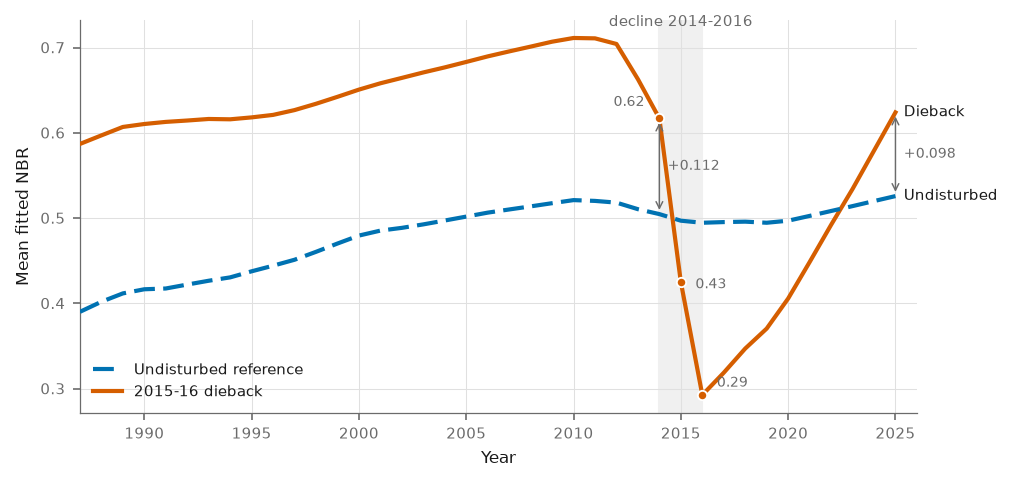

2014->2015 : 0.192 NBR  (59% of the loss)
2015->2016 : 0.132 NBR  (41% of the loss)
gap to reference: +0.112 in 2014, +0.098 in 2025


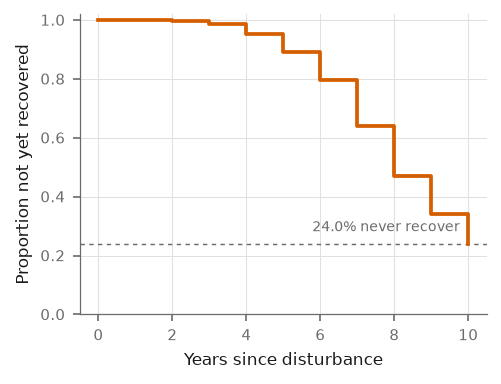

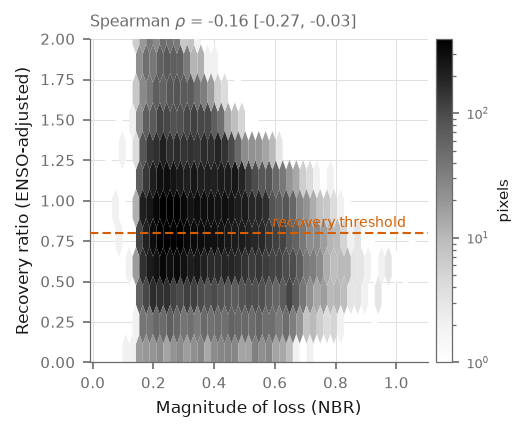

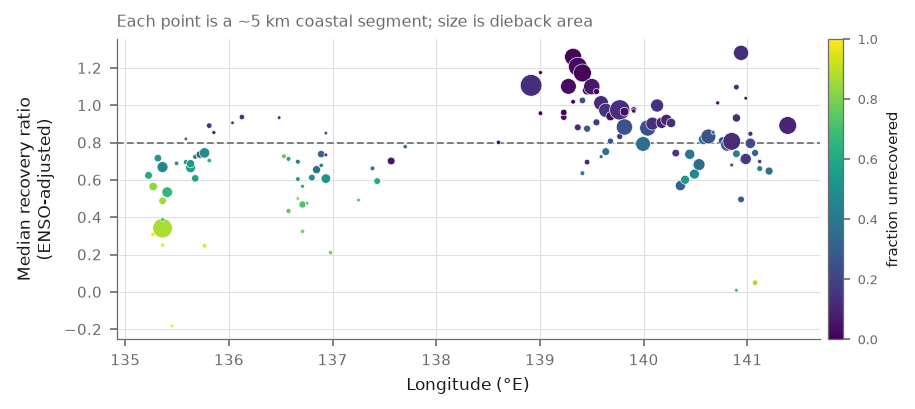

In [10]:
# Figure 1: mean fitted trajectories 
traj = pd.read_csv(DATA / "phase3_trajectories.csv")

fig, ax = plt.subplots(figsize=(W2, 3.4)); tidy(ax)

# The decline window, 2014-2016
ax.axvspan(2014, 2016, color="#f0f0f0", zorder=0)
ax.annotate("decline 2014-2016", xy=(2015, 0.985),
            xycoords=("data", "axes fraction"), ha="center",
            fontsize=7, color=C_MUTED)

ax.plot(traj.year, traj.fit_reference, color=C_REF, lw=2.0, ls=(0, (5, 2)),
        label="Undisturbed reference", zorder=4)
ax.plot(traj.year, traj.fit_dieback, color=C_DIEBACK, lw=2.0,
        label="2015-16 dieback", zorder=3)

# Mark the three decline vertices so the two-stage shape is visible rather
# than inferred: a straight line between 2014 and 2016 would imply equal
# steps, and they are not equal.
d = traj.set_index("year")["fit_dieback"]
ax.plot([2014, 2015, 2016], [d[2014], d[2015], d[2016]], "o",
        ms=4.5, color=C_DIEBACK, mec="white", mew=0.9, zorder=6)
for yr, dx, dy in ((2014, -22, 6), (2015, 7, -3), (2016, 7, 4)):
    ax.annotate(f"{d[yr]:.2f}", xy=(yr, d[yr]), xytext=(dx, dy),
                textcoords="offset points", fontsize=6.5, color=C_MUTED)

# The two gaps that carry the recovery argument
r = traj.set_index("year")["fit_reference"]
for yr in (2014, 2025):
    if yr in d.index and yr in r.index:
        ax.annotate("", xy=(yr, d[yr]), xytext=(yr, r[yr]),
                    arrowprops=dict(arrowstyle="<->", color=C_MUTED, lw=0.7))
        ax.annotate(f"+{d[yr]-r[yr]:.3f}", xy=(yr, (d[yr]+r[yr])/2),
                    xytext=(4, 0), textcoords="offset points",
                    fontsize=6.5, color=C_MUTED, va="center")

xe = traj.year.max()
ax.annotate("Dieback", xy=(xe, d[xe]), xytext=(4, 0),
            textcoords="offset points", fontsize=7, color=C_INK, va="center")
ax.annotate("Undisturbed", xy=(xe, r[xe]), xytext=(4, 0),
            textcoords="offset points", fontsize=7, color=C_INK, va="center")

ax.set_xlabel("Year"); ax.set_ylabel("Mean fitted NBR")
ax.set_xlim(traj.year.min(), traj.year.max() + 1)
ax.legend(frameon=False, loc="lower left")
fig.savefig(FIGDIR / "fig1_trajectories.png"); plt.show()

# Decline decomposition, stated numerically so the text cannot drift from it
s1, s2 = d[2014] - d[2015], d[2015] - d[2016]
print(f"2014->2015 : {s1:.3f} NBR  ({s1/(s1+s2):.0%} of the loss)")
print(f"2015->2016 : {s2:.3f} NBR  ({s2/(s1+s2):.0%} of the loss)")
print(f"gap to reference: {d[2014]-r[2014]:+.3f} in 2014, "
      f"{d[xe]-r[xe]:+.3f} in {int(xe)}")
RESULTS["decline_stage1_frac"] = float(s1/(s1+s2))
RESULTS["decline_2014_2015"] = float(s1)
RESULTS["decline_2015_2016"] = float(s2) 

#Figure 2: Kaplan-Meier 
fig, ax = plt.subplots(figsize=(W1, 2.6)); tidy(ax)
ax.step(km.t, km.S, where="post", color=C_DIEBACK, lw=1.8, zorder=3)
ax.fill_between(km.t, km.lo, km.hi, step="post",
                color=C_DIEBACK, alpha=0.18, lw=0, zorder=2)
ax.axhline(plateau, color=C_MUTED, lw=0.7, ls=(0, (3, 3)))
ax.annotate(f"{plateau:.1%} never recover", xy=(km.t.max(), plateau),
            xytext=(-4, 6), textcoords="offset points",
            ha="right", fontsize=6.5, color=C_MUTED)
ax.set_xlabel("Years since disturbance")
ax.set_ylabel("Proportion not yet recovered")
ax.set_ylim(0, 1.02)
fig.savefig(FIGDIR / "fig2_km.png"); plt.show()

# Figure 3: resistance vs recovery
fig, ax = plt.subplots(figsize=(W1, 2.8)); tidy(ax)
hb = ax.hexbin(px.magnitude, px.recovery_ratio_adj, gridsize=45,
               cmap="Greys", bins="log", mincnt=1, linewidths=0, zorder=2)
ax.axhline(RECOVERY_FRAC, color=C_DIEBACK, lw=1.0, ls=(0, (4, 2)), zorder=3)
ax.annotate("recovery threshold", xy=(px.magnitude.max(), RECOVERY_FRAC),
            xytext=(-3, 3), textcoords="offset points",
            ha="right", fontsize=6.5, color=C_DIEBACK)
cb = fig.colorbar(hb, ax=ax, pad=0.02); cb.set_label("pixels", fontsize=7)
cb.ax.tick_params(labelsize=6)
ax.set_xlabel("Magnitude of loss (NBR)")
ax.set_ylabel("Recovery ratio (ENSO-adjusted)")
ax.set_ylim(0, 2)
ax.set_title(f"Spearman $\\rho$ = {ind['rho']:+.2f} "
             f"[{ind['ci_low']:+.2f}, {ind['ci_high']:+.2f}]",
             fontsize=7.5, color=C_MUTED, loc="left")
fig.savefig(FIGDIR / "fig3_scatter.png"); plt.show()

# Figure 4: recovery along the coast 
if len(seg) < 10:
    print("skipped — not enough coastal segments")
else:
 fig, ax = plt.subplots(figsize=(W2, 2.6)); tidy(ax)
s = ax.scatter(seg.cell_lon, seg.recovery_ratio_adj,
               s=np.clip(seg.area_ha, 3, 120), c=seg.unrecovered_frac,
               cmap="viridis", vmin=0, vmax=1,
               edgecolor="white", linewidth=0.3, zorder=3)
ax.axhline(RECOVERY_FRAC, color=C_MUTED, lw=0.8, ls=(0, (4, 2)))
cb = fig.colorbar(s, ax=ax, pad=0.01)
cb.set_label("fraction unrecovered", fontsize=7); cb.ax.tick_params(labelsize=6)
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Median recovery ratio\n(ENSO-adjusted)")
ax.set_title("Each point is a ~5 km coastal segment; size is dieback area",
             fontsize=7.5, color=C_MUTED, loc="left")
fig.savefig(FIGDIR / "fig4_segments.png"); plt.show()

In [11]:
#Save the figures
def clean(o):
    if isinstance(o, dict):  return {k: clean(v) for k, v in o.items()}
    if isinstance(o, list):  return [clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, float) and not np.isfinite(o): return None
    return o

with open(TABDIR / "stats_summary.json", "w") as f:
    json.dump(clean(RESULTS), f, indent=2)

print("written:")
for p in sorted(list(TABDIR.glob('*')) + list(FIGDIR.glob('*'))):
    print("  ", p.relative_to(ROOT))

written:
   figures\.ipynb_checkpoints
   figures\fig1_trajectories.png
   figures\fig2_km.png
   figures\fig3_scatter.png
   figures\fig4_segments.png
   figures\fig6_study_area.png
   figures\fig7_recovery_map.png
   figures\fig8_patches.png
   tables\kaplan_meier.csv
   tables\patch_recovery.json
   tables\patch_stats.csv
   tables\segments.csv
   tables\stats_summary.json
   tables\table1_resilience.csv
